# GalMorphAI · 03 Modelado binario
**Seis modelos individuales · Avance 4 · Google Colab · versión 2.1.0**

Objetivo acordado: detectar **sin anillo (0)** frente a **con anillo (2, 4, 8, 12, 16)**. La columna `etiqueta_original` se conserva; se agrega `target_binario` sin modificar los archivos de entrada. El modelo no clasifica barras ni distingue tipos en esta etapa.

| Código | Significado confirmado por el usuario |
|---:|---|
| 0 | Ninguno |
| 2 | Nuclear |
| 4 | Interno |
| 8 | Externo |
| 12 | Interno + externo |
| 16 | Parcial |



In [2]:
import subprocess,sys
subprocess.check_call([sys.executable,'-m','pip','install','-q',
    'numpy>=1.26,<3','pandas>=2.2,<3','scikit-learn>=1.7,<2',
    'joblib>=1.4,<2','matplotlib>=3.8,<4',
    'google-cloud-storage>=2.18,<4'])


0

## 1. Protocolo de evaluación fijado antes de ver test
- Baseline con filas `extraido` y preprocesamiento `aprobado`. Excluir y reportar `revisar_features`, `error_features` y `sin_imagen_aprobada`; no convertir faltantes en negativos.
- 84 predictores de forma definidos explícitamente. No incluir etiquetas, IDs, coordenadas, fuente, QC o campos originales.
- Colapsar duplicados idénticos por objeto y rechazar contradicciones. Separar 80% entrenamiento / 20% test, estratificado por objetivo binario, semilla 42.
- Validación cruzada estratificada de cinco folds sólo dentro de entrenamiento. Imputación por mediana y escalado se ajustan en cada fold. Regresión logística, SVM y árbol admiten ponderación de clases; KNN, GaussianNB y MLP usan la distribución original. No se remuestrea el test.
- Comparar seis algoritmos individuales por AP media de validación: regresión logística, SVM, árbol de decisión, KNN, GaussianNB y MLP. AP resume precision–recall y no equivale al área trapezoidal. Seleccionar los dos primeros; explorar 24 configuraciones de cada uno con los mismos cinco folds. Incluir la configuración inicial entre candidatos. Elegir por AP; sólo un empate exacto se resuelve por tiempo de inferencia y nombre. No se garantiza una mejora.
- Elegir umbral por F1 de predicciones fuera del fold (OOF) del modelo seleccionado. Fijar modelo y umbral antes de evaluar test una sola vez.
- Reportar AP, ROC AUC, balanced accuracy, precisión, sensibilidad, F1, matriz de confusión y resultados por tipo original. Comparar AP con prevalencia positiva como referencia de ranking sin información.

Las probabilidades son scores no calibrados. El split aleatorio por objeto no garantiza independencia espacial ni elimina sesgos por cobertura o tamaño angular. El desempeño aplica a la población con imagen y QC elegibles, no a las 8,527 sin condiciones. Los descriptores son exploratorios de apertura fija, sensibles a fuentes vecinas/PSF y resolución; no prometen detección robusta de anillos nucleares.

Referencias: [scikit-learn: evitar fuga de información](https://scikit-learn.org/stable/common_pitfalls.html), [scikit-learn: búsqueda de hiperparámetros](https://scikit-learn.org/stable/modules/grid_search.html).


In [3]:
"""Modelado binario GalMorphAI; sin ejecución automática al importar."""
import io,json,hashlib,uuid,platform
from pathlib import Path
from decimal import Decimal,InvalidOperation
from datetime import datetime,timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import ParameterSampler
from time import perf_counter
import warnings
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (average_precision_score,roc_auc_score,balanced_accuracy_score,
    precision_score,recall_score,f1_score,confusion_matrix,precision_recall_curve,roc_curve)
from sklearn.inspection import permutation_importance
import joblib

LABEL_MAP={0:'ninguno',2:'nuclear',4:'interno',8:'externo',12:'interno+externo',16:'parcial'}
SHAPE_SUFFIXES=['r20_over_R','r50_over_R','r80_over_R','concentration_fixed',
 'gini_fixed','asymmetry_fixed','axis_ratio_moments','centroid_offset_over_R',
 'inner_fraction','outer_edge_fraction','radial_peak_over_R','radial_peak_contrast']+[
 f'radial_{i:02d}_relative' for i in range(16)]
PREDICTORS=[b+'_'+s for b in 'grz' for s in SHAPE_SUFFIXES]
MODEL_NAMES=['RegresionLogistica','SVM','ArbolDecision','KNN','GaussianNB','MLP']
MODEL_CFG=dict(version='2.1.0',seed=42,test_fraction=.2,folds=5,
               search_iterations=24,n_jobs=2,min_per_class=30,mlp_max_iter=500,
               objetivo='0=sin_anillo;2,4,8,12,16=con_anillo',
               seleccion='AP media CV; desempate exacto por tiempo de inferencia',
               umbral='F1 OOF entrenamiento')
SEARCH_SPACES={
 'RegresionLogistica':{'model__C':[.001,.01,.1,1,10,100], 'model__class_weight':[None,'balanced'], 'model__solver':['lbfgs','liblinear']},
 'SVM':{'model__C':[.01,.1,1,10,100], 'model__gamma':['scale',.001,.01,.1], 'model__kernel':['rbf','sigmoid'], 'model__class_weight':[None,'balanced']},
 'ArbolDecision':{'model__max_depth':[3,5,8,12,None], 'model__min_samples_leaf':[1,3,8,16], 'model__criterion':['gini','entropy'], 'model__class_weight':[None,'balanced']},
 'KNN':{'model__n_neighbors':[3,5,9,15,25,35], 'model__weights':['uniform','distance'], 'model__p':[1,2]},
 'GaussianNB':{'model__var_smoothing':list(np.logspace(-12,-2,31))},
 'MLP':{'model__hidden_layer_sizes':[(32,),(64,),(64,32),(128,64)], 'model__activation':['relu','tanh'], 'model__alpha':[.0001,.001,.01,.1], 'model__learning_rate_init':[.0001,.001,.01]}}
MODEL_NOTES={
 'RegresionLogistica':'Coeficientes interpretables; frontera lineal; escalado necesario.',
 'SVM':'Frontera no lineal; interpretación limitada; coste depende de vectores de soporte.',
 'ArbolDecision':'Reglas inspeccionables; profundidad controla complejidad y sobreajuste.',
 'KNN':'Predicción por vecinos; sensible a escala y dimensión; conserva entrenamiento.',
 'GaussianNB':'Rápido; supone independencia condicional y distribuciones gaussianas.',
 'MLP':'Red neuronal individual; no lineal, poco interpretable y sensible a convergencia.'}


def msha(data):return hashlib.sha256(data).hexdigest()
def mjson(x):return json.dumps(x,ensure_ascii=False,sort_keys=True,allow_nan=False).encode()


def label_code(value):
    try:
        d=Decimal(str(value).strip())
        if not d.is_finite() or d not in [Decimal(x) for x in LABEL_MAP]:raise ValueError('Código desconocido')
        return int(d)
    except InvalidOperation as e:raise ValueError('Etiqueta no numérica') from e


def load_dataset(csv_bytes,report_bytes,expected_rows=8527):
    report=json.loads(report_bytes)
    # Preservar IDs y etiquetas originales como texto; convertir sólo predictores explícitos.
    df=pd.read_csv(io.BytesIO(csv_bytes),dtype=str,keep_default_na=False)
    required={'objeto_id','indice_fila','etiqueta_original','estado_features',
              'estado_preprocesamiento',*PREDICTORS}
    if not required<=set(df.columns):raise ValueError('Faltan columnas de features: '+str(sorted(required-set(df.columns))))
    if len(df)!=expected_rows or report['resumen']['filas']!=expected_rows:
        raise ValueError('Número de filas incompatible con el catálogo')
    if df.indice_fila.duplicated().any() or df.objeto_id.eq('').any():raise ValueError('Índices repetidos o IDs vacíos')
    states=df.estado_features.value_counts().to_dict()
    if states!=report['resumen']['estados']:raise ValueError('CSV y JSON tienen estados distintos; usar el mismo checkpoint')
    if states.get('pendiente_features',0)>0:
        raise ValueError(f"Faltan {states['pendiente_features']} filas por extraer. Terminar notebook 02 con LIMITE=0.")
    allowed={'extraido','revisar_features','error_features','sin_imagen_aprobada'}
    if not set(states)<=allowed:raise ValueError('Estados desconocidos')
    df['anillos_codigo']=df.etiqueta_original.map(label_code)
    df['tipo_anillo']=df.anillos_codigo.map(LABEL_MAP)
    df['target_binario']=(df.anillos_codigo!=0).astype(int)
    for col in PREDICTORS:
        # Blancos son nulos legítimos; texto no numérico e infinito se rechazan.
        values=pd.to_numeric(df[col].replace('',np.nan),errors='raise')
        if np.isinf(values.to_numpy(dtype=float)).any():raise ValueError('Feature infinita: '+col)
        df[col]=values.astype(float)
    # Contrastar valores elegibles con el JSON hermano, no sólo su recuento.
    for row in df.loc[df.estado_features.isin(['extraido','revisar_features'])].to_dict('records'):
        result=report['resultados'].get(row['objeto_id'])
        if not result or result['estado']!=row['estado_features']:raise ValueError('Objeto ausente/incompatible en JSON')
        for col in PREDICTORS:
            v=result['features'].get(col);actual=row[col]
            if v is None:
                if not pd.isna(actual):raise ValueError('CSV/JSON difieren en nulo: '+col)
            elif not np.isclose(actual,float(v),rtol=1e-12,atol=1e-14,equal_nan=False):
                raise ValueError('CSV/JSON difieren en feature: '+col)
    # El baseline excluye casos QC pendientes de revisión; registra todas las exclusiones.
    excluded=df.loc[df.estado_features!='extraido'].copy()
    eligible=df.loc[df.estado_features=='extraido'].copy()
    if not eligible.estado_preprocesamiento.eq('aprobado').all():raise ValueError('Features sin preprocesamiento aprobado')
    if (df.groupby('objeto_id').anillos_codigo.nunique()>1).any():raise ValueError('Etiquetas contradictorias por objeto')
    if (df.groupby('objeto_id').estado_features.nunique()>1).any():raise ValueError('Estados contradictorios por objeto')
    for _,group in eligible.groupby('objeto_id'):
        if len(group)>1 and not group[PREDICTORS].eq(group[PREDICTORS].iloc[0]).fillna(False).all().all():
            # Comparar NaN como iguales, sin aceptar diferencias numéricas.
            arr=group[PREDICTORS].to_numpy()
            if not np.allclose(arr,arr[0],rtol=0,atol=0,equal_nan=True):raise ValueError('Features contradictorias en duplicados')
    eligible=eligible.sort_values('objeto_id').drop_duplicates('objeto_id').reset_index(drop=True)
    coverage=pd.crosstab(df.tipo_anillo,df.estado_features).reindex(LABEL_MAP.values(),fill_value=0)
    summary=dict(filas_total=len(df),filas_excluidas=len(excluded),objetos_elegibles=len(eligible),
        duplicados_colapsados=int((df.estado_features=='extraido').sum()-len(eligible)),
        estados=states,clases_elegibles=eligible.target_binario.value_counts().to_dict(),
        codigos=LABEL_MAP,semantica_origen='Definición proporcionada y aceptada por el usuario, 17-10-2026',
        csv_sha256=msha(csv_bytes),json_sha256=msha(report_bytes))
    return eligible,excluded,coverage,summary


def split_dataset(df,cfg):
    counts=df.target_binario.value_counts()
    if set(counts.index)!={0,1} or counts.min()<cfg['min_per_class']:
        raise ValueError('Muestras insuficientes en alguna clase binaria')
    train,test=train_test_split(np.arange(len(df)),test_size=cfg['test_fraction'],
                               stratify=df.target_binario,random_state=cfg['seed'])
    if set(df.iloc[train].objeto_id)&set(df.iloc[test].objeto_id):raise ValueError('Objeto compartido entre train/test')
    return train,test


def model_features(name,cfg):
    return cfg.get('image_features',{}).get(name,PREDICTORS)


def experiment_features(cfg):
    return list(dict.fromkeys(PREDICTORS+[c for v in cfg.get('image_features',{}).values() for c in v]))


def make_model(name,cfg):
    estimators={
      'RegresionLogistica':lambda:LogisticRegression(max_iter=2000,class_weight='balanced',random_state=cfg['seed']),
      'SVM':lambda:SVC(probability=True,class_weight='balanced',random_state=cfg['seed']),
      'ArbolDecision':lambda:DecisionTreeClassifier(max_depth=8,min_samples_leaf=3,class_weight='balanced',random_state=cfg['seed']),
      'KNN':lambda:KNeighborsClassifier(n_neighbors=9,n_jobs=cfg['n_jobs']),
      'GaussianNB':lambda:GaussianNB(),
      'MLP':lambda:MLPClassifier(hidden_layer_sizes=(64,),max_iter=cfg['mlp_max_iter'],random_state=cfg['seed'])}
    if name in cfg.get('image_features',{}):
        # Cabeza lineal binaria sobre un extractor neuronal congelado: un modelo, no un ensamble.
        estimators[name]=lambda:LogisticRegression(max_iter=2000,class_weight='balanced',random_state=cfg['seed'])
    if name not in estimators:raise ValueError(name)
    return Pipeline([('columns',ColumnTransformer([('selected','passthrough',model_features(name,cfg))],remainder='drop')),('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),('model',estimators[name]())])


def fit_balanced(model,X,y):
    # class_weight='balanced' se estima dentro del fit para los modelos que lo admiten.
    # KNN, NB y MLP conservan la distribución original, sin remuestreo artificial.
    model.fit(X,y)
    return model


def select_threshold(y,prob):
    thresholds=np.unique(np.r_[0.5,np.linspace(.05,.95,91)])
    scores=[f1_score(y,prob>=t,zero_division=0) for t in thresholds]
    # Desempate determinista: preferir umbral más próximo a 0.5.
    best=sorted(range(len(scores)),key=lambda i:(-scores[i],abs(thresholds[i]-.5),thresholds[i]))[0]
    return float(thresholds[best]),float(scores[best])


def metrics(y,prob,threshold):
    pred=(prob>=threshold).astype(int)
    return dict(average_precision=float(average_precision_score(y,prob)),
        roc_auc=float(roc_auc_score(y,prob)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
        precision=float(precision_score(y,pred,zero_division=0)),recall=float(recall_score(y,pred,zero_division=0)),
        f1=float(f1_score(y,pred,zero_division=0)),confusion_matrix=confusion_matrix(y,pred,labels=[0,1]).tolist(),
        prevalencia_positiva=float(np.mean(y)))


def evaluate_candidate(name,params,X,y,cv,cfg):
    oof=np.full(len(y),np.nan);rows=[]
    for fold,(a,b) in enumerate(cv,1):
        model=make_model(name,cfg).set_params(**params)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            start=perf_counter();fit_balanced(model,X.iloc[a],y[a]);fit_s=perf_counter()-start
            start=perf_counter();prob=model.predict_proba(X.iloc[b])[:,1];predict_s=perf_counter()-start
        oof[b]=prob
        row=metrics(y[b],prob,.5);row.pop('confusion_matrix')
        rows.append(dict(row,fold=fold,fit_seconds=fit_s,predict_seconds=predict_s,
                         warnings=' | '.join(sorted(set(str(w.message) for w in caught)))))
    if not np.isfinite(oof).all():raise ValueError('OOF incompleto')
    table=pd.DataFrame(rows)
    summary={k:float(table[k].mean()) for k in ['average_precision','roc_auc','balanced_accuracy','precision','recall','f1','fit_seconds','predict_seconds']}
    summary['ap_std']=float(table.average_precision.std(ddof=1))
    summary['warnings_count']=int(table.warnings.ne('').sum())
    return summary,oof,table


def train_baselines(df,cfg):
    train_idx,test_idx=split_dataset(df,cfg)
    train=df.iloc[train_idx].copy();test=df.iloc[test_idx].copy()
    X=train[experiment_features(cfg)];y=train.target_binario.to_numpy()
    folds=min(cfg['folds'],int(pd.Series(y).value_counts().min()))
    if folds<3:raise ValueError('Se necesitan al menos 3 folds')
    cv=list(StratifiedKFold(n_splits=folds,shuffle=True,random_state=cfg['seed']).split(X,y))
    base=[];details=[];cache={};probs={}
    for name in MODEL_NAMES+list(cfg.get('image_features',{})):
        stats,oof,table=evaluate_candidate(name,{},X,y,cv,cfg)
        base.append(dict(modelo=name,**stats));cache[name]=(stats,oof,{})
        probs[name]=oof;details.append(table.assign(modelo=name,etapa='inicial',candidato=0))
        print('Inicial:',name,'AP=',round(stats['average_precision'],4),flush=True)
    comparison=pd.DataFrame(base).sort_values(['average_precision','predict_seconds','modelo'],ascending=[False,True,True]).reset_index(drop=True)
    top2=comparison.modelo.head(2).tolist();search=[];finalists=[]
    for name in top2:
        # Incluir configuración inicial: el ajuste no obliga a empeorar ni a inventar mejora.
        best_stats,best_oof,best_params=cache[name]
        search.append(dict(modelo=name,candidato=0,parametros='{}',**best_stats))
        candidates=list(ParameterSampler((SEARCH_SPACES['RegresionLogistica'] if name in cfg.get('image_features',{}) else SEARCH_SPACES[name]),n_iter=cfg['search_iterations'],random_state=cfg['seed']))
        for number,params in enumerate(candidates,1):
            stats,oof,table=evaluate_candidate(name,params,X,y,cv,cfg)
            search.append(dict(modelo=name,candidato=number,parametros=json.dumps(params),**stats))
            details.append(table.assign(modelo=name,etapa='ajuste',candidato=number))
            if stats['average_precision']>best_stats['average_precision']:
                best_stats,best_oof,best_params=stats,oof,params
            print('Ajuste:',name,number,'/',len(candidates),'AP=',round(stats['average_precision'],4),flush=True)
        cache[name]=(best_stats,best_oof,best_params)
        initial=float(comparison.set_index('modelo').loc[name,'average_precision'])
        finalists.append(dict(modelo=name,ap_inicial=initial,mejora_ap=best_stats['average_precision']-initial,
            parametros=json.dumps(best_params),consideraciones=MODEL_NOTES.get(name,'Extractor neuronal congelado; se ajusta sólo la cabeza. Interpretabilidad limitada y coste adicional de extracción.'),**best_stats))
    tuned=pd.DataFrame(finalists).sort_values(['average_precision','predict_seconds','modelo'],ascending=[False,True,True]).reset_index(drop=True)
    winner=tuned.iloc[0].modelo;stats,oof,params=cache[winner]
    threshold,oof_f1=select_threshold(y,oof)
    start=perf_counter();selected=fit_balanced(make_model(winner,cfg).set_params(**params),X,y)
    final_fit_s=perf_counter()-start
    # El test nunca participa en ranking, búsqueda ni umbral.
    start=perf_counter();test_prob=selected.predict_proba(test[experiment_features(cfg)])[:,1];test_predict_s=perf_counter()-start
    test_metrics=metrics(test.target_binario.to_numpy(),test_prob,threshold)
    predictions=test[['objeto_id','etiqueta_original','anillos_codigo','tipo_anillo','target_binario']].copy()
    predictions['score_con_anillo']=test_prob;predictions['prediccion_binaria']=(test_prob>=threshold).astype(int)
    subtype=[]
    for code,name in LABEL_MAP.items():
        sub=predictions[predictions.anillos_codigo==code]
        subtype.append(dict(codigo=code,tipo=name,n_test=len(sub),fraccion_clasificada_con_anillo=float(sub.prediccion_binaria.mean()) if len(sub) else None))
    winner_features=model_features(winner,cfg)
    importance=permutation_importance(selected,X[winner_features],y,scoring='average_precision',n_repeats=3,random_state=cfg['seed'],n_jobs=1)
    importance_table=pd.DataFrame(dict(feature=winner_features,importance_train=importance.importances_mean,std_train=importance.importances_std)).sort_values('importance_train',ascending=False)
    split=df[['objeto_id','etiqueta_original','tipo_anillo']].copy();split['split']='train';split.loc[test.index,'split']='test'
    oof_table=train[['objeto_id','target_binario']].copy()
    for name,p in probs.items():oof_table[name+'_inicial_oof']=p
    oof_table['final_ajustado_oof']=oof
    runner=tuned.iloc[1]
    justification=(f"Se elige {winner} por AP media CV={stats['average_precision']:.4f}, frente a "
        f"{runner.modelo}={runner.average_precision:.4f}. F1 CV a umbral 0.5={stats['f1']:.4f}; "
        f"sensibilidad={stats['recall']:.4f}; ajuste medio/fold={stats['fit_seconds']:.3f}s; "
        f"inferencia media/fold={stats['predict_seconds']:.3f}s. {MODEL_NOTES.get(winner,'Extractor neuronal congelado; clasificación por cabeza lineal. Interpretabilidad limitada; extracción de imágenes tiene coste adicional.')} "
        'Se prioriza el ranking de candidatos con anillo; se acepta esta limitación de interpretación/coste. '
        'Las diferencias de CV son descriptivas, no prueba de significación. Revisar alertas de convergencia antes de entregar.')
    summary=dict(modelo_elegido=winner,top2=top2,parametros_finales=params,justificacion=justification,
        cv_average_precision=comparison.set_index('modelo').average_precision.to_dict(),umbral=threshold,
        f1_oof_para_umbral=oof_f1,metricas_test=test_metrics,por_tipo=subtype,n_train=len(train),n_test=len(test),folds=folds,
        final_fit_seconds=final_fit_s,test_predict_seconds=test_predict_s,
        test_previamente_inspeccionado=cfg.get('test_previamente_inspeccionado',False),
        vision=cfg.get('vision_provenance'),
        nota='CV reutilizada para selección y ajuste: optimista. Test sólo es independiente si no fue inspeccionado en iteraciones anteriores; scores no necesariamente calibrados.',
        sesgos='Split por objeto, no espacial; exclusiones QC y desbalance por subtipo limitan conclusiones.')
    return dict(model=selected,summary=summary,cv=pd.concat(details,ignore_index=True),comparativa=comparison,
        busqueda=pd.DataFrame(search),ajustados=tuned,split=split,test_predictions=predictions,oof=oof_table,importance=importance_table)


def save_training(result,excluded,coverage,input_summary,cfg,output_root):
    folder=Path(output_root)/(datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'-'+uuid.uuid4().hex[:12])
    folder.mkdir(parents=True,exist_ok=False)
    def save(name,data):
        with (folder/name).open('xb') as f:f.write(data)
    provenance=dict(config=cfg,entrada=input_summary,labels=LABEL_MAP,predictors=model_features(result['summary']['modelo_elegido'],cfg),
        versiones={p:version(p) for p in ['numpy','pandas','scikit-learn','joblib']},
        python=platform.python_version(),fecha_utc=datetime.now(timezone.utc).isoformat())
    save('provenance.json',mjson(provenance));save('metricas.json',mjson(result['summary']))
    for key in ['cv','comparativa','busqueda','ajustados','split','test_predictions','oof','importance']:
        save(key+'.csv',result[key].to_csv(index=False).encode())
    save('excluidos.csv',excluded[['objeto_id','etiqueta_original','estado_features','estado_preprocesamiento']].to_csv(index=False).encode())
    save('cobertura_por_tipo.csv',coverage.to_csv().encode())
    buffer=io.BytesIO();joblib.dump(dict(pipeline=result['model'],threshold=result['summary']['umbral'],
        features=model_features(result['summary']['modelo_elegido'],cfg),labels=LABEL_MAP,model_name=result['summary']['modelo_elegido'],vision=cfg.get('vision_provenance')),buffer);save('modelo.joblib',buffer.getvalue())
    save('checksums.json',mjson({p.name:msha(p.read_bytes()) for p in folder.iterdir() if p.is_file()}))
    return folder


## 2. Pruebas sintéticas
Prueban mapeo de etiquetas, controles de completitud, exclusiones QC, asociación CSV/JSON, duplicados, separación, imputación sin test, selección de umbral y comparación de los seis algoritmos y ajuste de dos con búsqueda reducida. Sus métricas no describen galaxias reales.


In [4]:
import unittest,tempfile
from unittest.mock import patch


def synthetic_table(n=120):
    rng=np.random.default_rng(42);y=np.arange(n)%2
    values=rng.normal(size=(n,len(PREDICTORS)));values[:,0]+=y*2
    df=pd.DataFrame(values,columns=PREDICTORS)
    df['objeto_id']=[f'obj-{i:04}' for i in range(n)];df['indice_fila']=np.arange(n)
    df['etiqueta_original']=np.where(y,'4.0','0.0');df['estado_features']='extraido'
    df['estado_preprocesamiento']='aprobado'
    return df


def make_report(df):
    results={}
    for row in df.to_dict('records'):
        results[row['objeto_id']]=dict(estado=row['estado_features'],features={
            k:None if pd.isna(row[k]) else float(row[k]) for k in PREDICTORS})
    return mjson(dict(resumen={'filas':len(df),'estados':df.estado_features.value_counts().to_dict()},resultados=results))

class TestModeling(unittest.TestCase):
    def setUp(self):self.df=synthetic_table();self.cfg=dict(MODEL_CFG,search_iterations=2,mlp_max_iter=30,folds=3,n_jobs=1)
    def load(self,df):return load_dataset(df.to_csv(index=False).encode(),make_report(df),expected_rows=len(df))
    def test_label_mapping(self):
        self.assertEqual([int(label_code(x)!=0) for x in ['0.0','2','4.0','8','12','16.0']],[0,1,1,1,1,1])
        with self.assertRaises(ValueError):label_code('3')
        with self.assertRaises(ValueError):label_code('0.01')
    def test_no_label_predictor(self):
        eligible,_,_,_=self.load(self.df)
        self.assertEqual(len(PREDICTORS),84)
        self.assertFalse(set(PREDICTORS)&{'target_binario','etiqueta_original','anillos_codigo','objeto_id'})
        self.assertEqual(eligible.etiqueta_original.unique().tolist(),['0.0','4.0'])
    def test_pending_blocks(self):
        self.df.loc[0,'estado_features']='pendiente_features'
        with self.assertRaisesRegex(ValueError,'LIMITE=0'):self.load(self.df)
    def test_qc_excluded(self):
        self.df.loc[0,'estado_features']='revisar_features'
        eligible,excluded,_,_=self.load(self.df)
        self.assertEqual(len(excluded),1);self.assertEqual(len(eligible),119)
    def test_split_no_shared_objects(self):
        eligible,_,_,_=self.load(self.df);a,b=split_dataset(eligible,self.cfg)
        self.assertFalse(set(eligible.iloc[a].objeto_id)&set(eligible.iloc[b].objeto_id))
        c,d=split_dataset(eligible,self.cfg);np.testing.assert_array_equal(a,c)
    def test_duplicates_grouped(self):
        row=self.df.iloc[[0]].copy();row['indice_fila']=120
        eligible,_,_,summary=self.load(pd.concat([self.df,row],ignore_index=True))
        self.assertEqual(len(eligible),120);self.assertEqual(summary['duplicados_colapsados'],1)
    def test_conflicting_labels(self):
        self.df.loc[1,'objeto_id']=self.df.loc[0,'objeto_id']
        with self.assertRaises(ValueError):self.load(self.df)
    def test_csv_json_mismatch(self):
        data=make_report(self.df);self.df.loc[0,PREDICTORS[0]]+=1
        with self.assertRaises(ValueError):load_dataset(self.df.to_csv(index=False).encode(),data,120)
    def test_imputation_train_only(self):
        X=pd.DataFrame({k:[1.,2.,np.nan,3.] for k in PREDICTORS});y=np.array([0,1,0,1])
        model=fit_balanced(make_model('ArbolDecision',self.cfg),X,y)
        self.assertEqual(model['imputer'].statistics_[0],2.)
        model.predict_proba(pd.DataFrame({k:[9999.] for k in PREDICTORS}))
        self.assertEqual(model['imputer'].statistics_[0],2.)
    def test_six_individual_algorithms(self):
        models=[make_model(n,self.cfg)['model'] for n in MODEL_NAMES]
        self.assertEqual(len({type(m) for m in models}),6)
        self.assertFalse(any(type(m).__module__.startswith('sklearn.ensemble') for m in models))
    def test_search_spaces(self):
        for name in MODEL_NAMES:
            candidates=list(ParameterSampler(SEARCH_SPACES[name],n_iter=24,random_state=42))
            self.assertEqual(len(candidates),24)
            for params in candidates:make_model(name,self.cfg).set_params(**params)
    def test_threshold_uses_scores(self):
        t,f=select_threshold(np.array([0,0,1,1]),np.array([.1,.2,.7,.8]))
        self.assertEqual(f,1.);self.assertAlmostEqual(t,.5)
    def test_end_to_end_synthetic(self):
        eligible,excluded,coverage,summary=self.load(self.df)
        expected_train,expected_test=split_dataset(eligible,self.cfg)
        original=evaluate_candidate
        seen=[]
        def guarded(name,params,X,y,cv,cfg):
            self.assertEqual(set(X.index),set(eligible.iloc[expected_train].index))
            self.assertFalse(set(X.index)&set(eligible.iloc[expected_test].index))
            seen.append(name)
            return original(name,params,X,y,cv,cfg)
        with patch.dict(train_baselines.__globals__,evaluate_candidate=guarded):
            result=train_baselines(eligible,self.cfg)
        self.assertEqual(len(seen),10)
        self.assertEqual(result['summary']['n_test'],24)
        self.assertEqual(len(result['oof']),96)
        self.assertEqual(len(result['comparativa']),6)
        self.assertEqual(len(result['ajustados']),2)
        self.assertEqual(len(result['busqueda']),6)
        self.assertTrue(result['ajustados'].mejora_ap.ge(0).all())
        self.assertEqual(len(result['cv']),30)
        self.assertIn(result['summary']['modelo_elegido'],result['summary']['top2'])
        self.assertTrue(result['comparativa'].average_precision.is_monotonic_decreasing)
        with tempfile.TemporaryDirectory() as tmp:
            folder=save_training(result,excluded,coverage,summary,self.cfg,tmp)
            hashes=json.loads((folder/'checksums.json').read_bytes())
            self.assertTrue(all(msha((folder/name).read_bytes())==digest for name,digest in hashes.items()))
            bundle=joblib.load(folder/'modelo.joblib')
            self.assertEqual(bundle['features'],PREDICTORS)


def modeling_tests():
    result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(TestModeling))
    if not result.wasSuccessful():raise AssertionError('Fallaron pruebas de modelado')
    return result

modeling_tests()


test_conflicting_labels (__main__.TestModeling.test_conflicting_labels) ... ok
test_csv_json_mismatch (__main__.TestModeling.test_csv_json_mismatch) ... ok
test_duplicates_grouped (__main__.TestModeling.test_duplicates_grouped) ... ok
test_end_to_end_synthetic (__main__.TestModeling.test_end_to_end_synthetic) ... 

Inicial: RegresionLogistica AP= 0.7232
Inicial: SVM AP= 0.454
Inicial: ArbolDecision AP= 0.7246
Inicial: KNN AP= 0.5839
Inicial: GaussianNB AP= 0.7774
Inicial: MLP AP= 0.6496
Ajuste: GaussianNB 1 / 2 AP= 0.7774
Ajuste: GaussianNB 2 / 2 AP= 0.7774
Ajuste: ArbolDecision 1 / 2 AP= 0.8126
Ajuste: ArbolDecision 2 / 2 AP= 0.6602


ok
test_imputation_train_only (__main__.TestModeling.test_imputation_train_only) ... ok
test_label_mapping (__main__.TestModeling.test_label_mapping) ... ok
test_no_label_predictor (__main__.TestModeling.test_no_label_predictor) ... ok
test_pending_blocks (__main__.TestModeling.test_pending_blocks) ... ok
test_qc_excluded (__main__.TestModeling.test_qc_excluded) ... ok
test_search_spaces (__main__.TestModeling.test_search_spaces) ... ok
test_six_individual_algorithms (__main__.TestModeling.test_six_individual_algorithms) ... ok
test_split_no_shared_objects (__main__.TestModeling.test_split_no_shared_objects) ... ok
test_threshold_uses_scores (__main__.TestModeling.test_threshold_uses_scores) ... ok

----------------------------------------------------------------------
Ran 13 tests in 12.050s

OK


<unittest.runner.TextTestResult run=13 errors=0 failures=0>

## 3. Seleccionar el checkpoint final de features
Usar **el CSV y JSON del mismo checkpoint de `02_feature_engineering.ipynb`**, no los archivos de preprocesamiento. Puede ser una ruta local de Colab (sin GCP) o una ruta de objeto GCS. Para entrada local, subir ambos archivos al mismo directorio y seleccionar el `.json`; se busca su `.csv` hermano.

No se necesita descargar FITS otra vez: este notebook lee sólo tablas de características. Cargar el snapshot final y revisar cobertura de todas las etiquetas antes del entrenamiento. El análisis de exclusiones por tipo sirve para detectar sesgos de selección, no para elegir variables usando test.


In [5]:
#@title Configuración de entrada
ORIGEN = 'GCP' #@param ["local", "GCP"]
CHECKPOINT_FEATURES_JSON = 'gs://galmorphai-science/features/v1/d33b763ffed5bfa03e33b02a/ejecuciones/b73486a75d744e1eaf7c2ad1983fb2cf/checkpoint-08504.json' #@param {type:"string"}
PROYECTO = 'brave-server-511721-p7' #@param {type:"string"}
BUCKET = 'galmorphai-science' #@param {type:"string"}
ENTORNO = 'Colab' #@param ["Colab", "ADC"]
CONFIG_MODELO = dict(MODEL_CFG)
DIRECTORIO_MODELOS = str(Path.cwd()/'galmorphai_modelos')


In [6]:
#@title Cargar tablas y revisar cobertura (autoriza lecturas si ORIGEN=GCP)
CARGAR_DATOS = True #@param {type:"boolean"}
datos_modelo = None
cliente_modelo = None
if CARGAR_DATOS:
    if not CHECKPOINT_FEATURES_JSON.endswith('.json'):
        raise ValueError('Seleccionar un checkpoint JSON de features completo y su CSV hermano')
    if ORIGEN=='local':
        archivo=Path(CHECKPOINT_FEATURES_JSON)
        json_bytes=archivo.read_bytes();csv_bytes=archivo.with_suffix('.csv').read_bytes()
    else:
        import google.auth
        from google.cloud import storage
        if ENTORNO=='Colab':
            from google.colab import auth
            auth.authenticate_user(project_id=PROYECTO)
        credentials,_=google.auth.default()
        cliente_modelo=storage.Client(project=PROYECTO,credentials=credentials)
        bucket_modelo=cliente_modelo.get_bucket(BUCKET,timeout=120)
        if bucket_modelo.location.lower()!='us-central1':raise ValueError('Región inesperada')
        key=CHECKPOINT_FEATURES_JSON
        if key.startswith('gs://'+BUCKET+'/'):key=key[len('gs://'+BUCKET+'/'):]
        if not key.startswith('features/v1/'):raise ValueError('Se requiere checkpoint de features/v1/')
        def leer_objeto_modelo(name):
            blob=bucket_modelo.get_blob(name,timeout=120)
            if blob is None:raise FileNotFoundError(name)
            data=blob.download_as_bytes(if_generation_match=int(blob.generation),checksum='crc32c',timeout=120)
            expected=(blob.metadata or {}).get('sha256')
            if expected and msha(data)!=expected:raise ValueError('SHA-256 incompatible')
            return data
        json_bytes=leer_objeto_modelo(key);csv_bytes=leer_objeto_modelo(key[:-5]+'.csv')
    datos_modelo,excluidos_modelo,cobertura_modelo,resumen_entrada=load_dataset(csv_bytes,json_bytes)
    print('Objeto elegibles:',len(datos_modelo),'| Filas excluidas:',len(excluidos_modelo))
    display(cobertura_modelo)
    display(pd.crosstab(datos_modelo.tipo_anillo,datos_modelo.target_binario))
else:
    print('Carga desactivada. Terminar 02 y seleccionar su checkpoint final.')


Objeto elegibles: 7460 | Filas excluidas: 1067


estado_features,extraido,revisar_features,sin_imagen_aprobada
tipo_anillo,,,
ninguno,5779,866,14
nuclear,98,11,2
interno,768,85,4
externo,171,15,0
interno+externo,335,35,2
parcial,309,32,1


target_binario,0,1
tipo_anillo,,
externo,0,171
interno,0,768
interno+externo,0,335
ninguno,5779,0
nuclear,0,98
parcial,0,309


## 3B. CNN y Vision Transformer — ampliación del Avance 4

Se conservan los seis modelos tabulares y se agregan **CNN ResNet-18** y **Vision Transformer ViT-B/16**, ambos preentrenados en ImageNet. Cada alternativa usa un extractor congelado y una cabeza lineal binaria (regresión logística); se ajustan regularización, solver y ponderación. Es transferencia de aprendizaje con **cabeza entrenable**, no fine-tuning de todas las capas. Cada modelo produce su propia predicción; no se combinan votos ni probabilidades.

Con esta sección activa se comparan **ocho modelos individuales** con las mismas galaxias, partición y cinco folds. Se eligen los dos mejores entre los ocho por AP de CV y se exploran 24 configuraciones de cada finalista. Si CNN/ViT no quedan entre los dos mejores, se reportan sus resultados sin forzar su selección. Con ocho modelos hay 280 ajustes de CV más el ajuste final, además de extracción neuronal y trabajo interno de SVM.

Las redes reciben FITS derivados existentes: `NORMALIZED` + `MASK`, bandas grz en ese orden. Por imagen y banda se escala por percentiles 1–99, se redimensiona TODO el campo a 224×224 y se aplica la normalización numérica de ImageNet. Esto **no convierte grz en RGB físico**, pierde información fotométrica absoluta y difiere del recorte central estándar: se evita recortar anillos externos. Los pesos de fotografías naturales pueden no transferirse bien a galaxias; la mejora debe medirse. ResNet tiene sesgo local convolucional; ViT usa atención entre parches y demanda más memoria/cómputo.

Se calculan representaciones de todas las imágenes con redes congeladas y sin etiquetas. No se aprende ninguna transformación de la población completa; imputación, escalado de representaciones y cabeza se ajustan dentro de cada fold. Las filas excluidas por QC y las 23 imágenes faltantes siguen excluidas. SHA-256 de cada FITS debe coincidir con el checkpoint de features. La caché local está ligada al hash de imagen, versiones, pesos y receta; permite reanudar extracción. La búsqueda de cabezas, como antes, no tiene reanudación parcial.

**Coste y autorización:** todo está desactivado por defecto. Activar la celda permite instalar dependencias y hacer cómputo local/Colab. La descarga de pesos (~375 MB entre ambos modelos) y lectura de FITS en GCP tienen casillas separadas. CPU funciona, pero GPU puede reducir el tiempo de extracción; el notebook no provisiona GPU ni recursos de nube. No se escriben objetos en GCP en esta etapa. Conservar la caché si cambia el runtime. Los segundos de CV reflejan la cabeza sobre representaciones cacheadas, **no latencia completa de las redes**; el coste de extracción se reporta por separado en provenance y en la salida de preparación.

**Test ya inspeccionado:** las curvas del experimento previo ya fueron vistas. Mantener el mismo test permite una comparación retrospectiva, pero no constituye una nueva prueba ciega. Seleccionar modelos sólo por CV; para una afirmación confirmatoria se requiere otro conjunto externo nunca inspeccionado. Cambiar la semilla no hace que las galaxias ya vistas vuelvan a ser independientes.

Para activar: cargar primero el checkpoint completo; establecer `PREPARAR_IMAGENES=True`, autorizar pesos si no están cacheados y elegir FITS locales (carpeta que contiene `processed/v1/...`) o autorizar lectura GCP. Después ejecutar la celda de entrenamiento. Los controles de entrenamiento y exportación siguen siendo independientes.

Referencias: [ResNet-18, Torchvision](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html), [ViT-B/16, Torchvision](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html). La extracción modifica explícitamente el preprocesamiento espacial estándar para conservar el campo.


In [7]:
"""Transferencia CNN/ViT. No importa torch ni lee nube al cargar este módulo."""
import io
import json
import hashlib
import time
from pathlib import Path
import numpy as np
import pandas as pd

VISION_RECIPE = dict(version='1.0.0',bands='grz',source='NORMALIZED',size=224,
    percentiles=[1,99],normalization='ImageNet mean/std sobre canales grz (no RGB físico)',
    cnn='ResNet18_Weights.IMAGENET1K_V1',vit='ViT_B_16_Weights.IMAGENET1K_V1',
    cnn_dim=512,vit_dim=768,training='backbone congelado; cabeza logística binaria ajustada por CV')
VISION_NAMES={'CNN_ResNet18':512,'ViT_B16':768}


def vision_sha(data):return hashlib.sha256(data).hexdigest()


def vision_image(data):
    from astropy.io import fits
    with fits.open(io.BytesIO(data),memmap=False,checksum=True) as h:
        h.verify('exception')
        for ext in h:
            if 'CHECKSUM' in ext.header and ext.verify_checksum()!=1:raise ValueError('CHECKSUM FITS inválido')
            if 'DATASUM' in ext.header and ext.verify_datasum()!=1:raise ValueError('DATASUM FITS inválido')
        if [h[0].header.get(f'BAND{i}') for i in range(3)]!=list('grz'):raise ValueError('Bandas distintas de grz')
        image=np.asarray(h['NORMALIZED'].data,dtype=np.float32).copy()
        mask=np.asarray(h['MASK'].data)
        if image.shape!=(3,256,256) or mask.shape!=image.shape:raise ValueError('Dimensiones FITS incompatibles')
        valid=np.isfinite(image)&((mask&1)==0)
    output=np.zeros_like(image)
    for c in range(3):
        values=image[c][valid[c]]
        if len(values)<.95*256*256:raise ValueError('Más de 5% inválido en banda')
        lo,hi=np.percentile(values,VISION_RECIPE['percentiles'])
        if not np.isfinite([lo,hi]).all() or hi<=lo:raise ValueError('Banda sin rango de señal')
        output[c][valid[c]]=np.clip((values-lo)/(hi-lo),0,1)
    return output


def vision_tensor(images,torch,device):
    # Redimensionar TODO el campo; no recortar anillos externos con center crop.
    x=torch.as_tensor(np.stack(images),dtype=torch.float32,device=device)
    x=torch.nn.functional.interpolate(x,size=(224,224),mode='bilinear',align_corners=False,antialias=True)
    mean=x.new_tensor([.485,.456,.406])[None,:,None,None]
    std=x.new_tensor([.229,.224,.225])[None,:,None,None]
    return (x-mean)/std


def assemble_embeddings(df,records):
    if set(records)!=set(df.objeto_id) or df.objeto_id.duplicated().any():
        raise ValueError('Embeddings deben corresponder exactamente a los objetos elegibles, sin duplicados')
    columns={name:[f'{name}_{i:04}' for i in range(dim)] for name,dim in VISION_NAMES.items()}
    arrays=[]
    for name,dim in VISION_NAMES.items():
        a=np.stack([records[oid][name] for oid in df.objeto_id])
        if a.shape!=(len(df),dim) or not np.isfinite(a).all():raise ValueError('Embeddings inválidos: '+name)
        arrays.append(pd.DataFrame(a,columns=columns[name],index=df.index))
    # No concatenar columnas repetidas al volver a ejecutar.
    base=df.drop(columns=[c for names in columns.values() for c in names if c in df],errors='ignore')
    return pd.concat([base,*arrays],axis=1),columns


def load_vision_backbones(allow_download,device):
    import torch,torchvision
    torch.set_num_threads(2)
    from torchvision.models import resnet18,ResNet18_Weights,vit_b_16,ViT_B_16_Weights
    from urllib.parse import urlparse
    specs=[('CNN_ResNet18',resnet18,ResNet18_Weights.IMAGENET1K_V1),
           ('ViT_B16',vit_b_16,ViT_B_16_Weights.IMAGENET1K_V1)]
    if device=='cuda' and not torch.cuda.is_available():raise ValueError('No hay GPU CUDA en este runtime')
    models={};hashes={}
    for name,builder,weights in specs:
        checkpoint=Path(torch.hub.get_dir())/'checkpoints'/Path(urlparse(weights.url).path).name
        if not checkpoint.exists() and not allow_download:
            raise ValueError('Faltan pesos preentrenados; autorizar descarga explícitamente: '+name)
        model=builder(weights=weights)
        if name=='CNN_ResNet18':model.fc=torch.nn.Identity()
        else:model.heads=torch.nn.Identity()
        model.requires_grad_(False);model.eval();model.to(device)
        models[name]=model;hashes[name]=vision_sha(checkpoint.read_bytes())
    return torch,models,dict(torch=torch.__version__,torchvision=torchvision.__version__,weights_sha256=hashes)


def prepare_vision(df,feature_report,read_fits,cache_root,allow_weights=False,device='cpu',batch_size=8):
    if batch_size<1:raise ValueError('batch_size debe ser positivo')
    torch,models,versions=load_vision_backbones(allow_weights,device)
    recipe=dict(VISION_RECIPE,**versions)
    recipe_id=vision_sha(json.dumps(recipe,sort_keys=True).encode())[:24]
    cache=Path(cache_root)/recipe_id;cache.mkdir(parents=True,exist_ok=True)
    records={};timings={name:0. for name in models};uncached=0;start=time.perf_counter()
    pending=[]
    def flush():
        nonlocal uncached
        if not pending:return
        x=vision_tensor([a[2] for a in pending],torch,device)
        arrays={}
        with torch.inference_mode():
            for name,model in models.items():
                if device=='cuda':torch.cuda.synchronize()
                t=time.perf_counter();arr=model(x).cpu().numpy()
                if device=='cuda':torch.cuda.synchronize()
                timings[name]+=time.perf_counter()-t;arrays[name]=arr
        for i,(oid,filename,_) in enumerate(pending):
            vectors={name:arr[i].astype(np.float32) for name,arr in arrays.items()}
            if any(v.shape!=(VISION_NAMES[n],) or not np.isfinite(v).all() for n,v in vectors.items()):
                raise ValueError('Salida de extractor inválida')
            buffer=io.BytesIO();np.savez_compressed(buffer,**vectors);data=buffer.getvalue()
            # Archivos terminados de forma atómica; caché derivada local, nunca modifica FITS.
            temp=filename.with_suffix('.partial');temp.write_bytes(data);temp.replace(filename)
            filename.with_suffix('.sha256').write_text(vision_sha(data))
            records[oid]=vectors;uncached+=1
        pending.clear()
    for i,oid in enumerate(df.objeto_id,1):
        record=feature_report['resultados'].get(oid,{})
        if record.get('estado')!='extraido':raise ValueError('Objeto no elegible en checkpoint: '+oid)
        key=record.get('source_key','');digest=record.get('source_sha256','')
        if not key.startswith('processed/v1/') or len(digest)!=64:raise ValueError('Provenance FITS incompleta')
        filename=cache/(vision_sha((oid+digest).encode())+'.npz')
        checksum=filename.with_suffix('.sha256')
        if filename.exists() and checksum.exists():
            data=filename.read_bytes()
            if vision_sha(data)!=checksum.read_text().strip():raise ValueError('Caché corrupta: '+str(filename))
            with np.load(io.BytesIO(data),allow_pickle=False) as z:records[oid]={n:z[n].copy() for n in models}
        else:
            data=read_fits(key)
            if vision_sha(data)!=digest:raise ValueError('SHA FITS no coincide con checkpoint: '+oid)
            pending.append((oid,filename,vision_image(data)))
            if len(pending)>=batch_size:flush()
        if i%100==0:print('CNN/ViT:',i,'/',len(df),'objetos',flush=True)
    flush()
    enriched,columns=assemble_embeddings(df,records)
    provenance=dict(recipe=recipe,cache_id=recipe_id,device=device,objects=len(df),
        uncached_objects=uncached,backbone_seconds=timings,wall_seconds=time.perf_counter()-start,
        nota_tiempos='Backbones medidos sólo para objetos no cacheados; no comparar con tiempos de cabeza como si fueran end-to-end.')
    (cache/'ultima_preparacion.json').write_text(json.dumps(provenance,indent=2))
    return enriched,columns,provenance


def predict_vision_fits(bundle,data,torch,models,device='cpu'):
    """Inferencia con un bundle propio y backbones cargados con la receta/weights guardados.

    Al cargar: comparar versions['weights_sha256'] de load_vision_backbones con
    bundle['vision']['recipe']['weights_sha256']; detenerse ante diferencias.
    No utilizar esta función para un ganador tabular.
    """
    name=bundle['model_name']
    if name not in VISION_NAMES:raise ValueError('El modelo guardado no es CNN/ViT')
    expected=bundle['vision']['recipe']
    if any(expected.get(k)!=v for k,v in VISION_RECIPE.items()):raise ValueError('Receta de imagen incompatible')
    tensor=vision_tensor([vision_image(data)],torch,device)
    with torch.inference_mode():vector=models[name](tensor).cpu().numpy()
    frame=pd.DataFrame(vector,columns=bundle['features'])
    score=float(bundle['pipeline'].predict_proba(frame)[0,1])
    return dict(score_con_anillo=score,prediccion_binaria=int(score>=bundle['threshold']))


In [8]:
#@title Preparar CNN y ViT para Avance 4 (opcional; ejecutar después de cargar las tablas)
PREPARAR_IMAGENES = True #@param {type:"boolean"}
AUTORIZAR_DESCARGA_PESOS = True #@param {type:"boolean"}
AUTORIZAR_LECTURA_FITS_GCP = True #@param {type:"boolean"}
DIRECTORIO_FITS_LOCAL = '' #@param {type:"string"}
CACHE_VISION = '/content/galmorphai_cache_vision' #@param {type:"string"}
DISPOSITIVO_VISION = 'cuda' #@param ["cpu", "cuda"]
LOTE_VISION = 8 #@param {type:"integer"}
# El test ya fue inspeccionado en el experimento previo: preservar esta advertencia.
CONFIG_MODELO['test_previamente_inspeccionado'] = True
if PREPARAR_IMAGENES:
    if datos_modelo is None:raise ValueError('Primero cargar el checkpoint completo de features')
    if not DIRECTORIO_FITS_LOCAL.strip() and not AUTORIZAR_LECTURA_FITS_GCP:
        raise ValueError('Indicar carpeta local de FITS o autorizar lectura GCP')
    import subprocess,sys
    subprocess.check_call([sys.executable,'-m','pip','install','-q','torch>=2.5,<3','torchvision>=0.20,<1','astropy>=6,<8'])
    if AUTORIZAR_LECTURA_FITS_GCP and not DIRECTORIO_FITS_LOCAL.strip():
        import google.auth
        from google.cloud import storage
        if cliente_modelo is None:
            if ENTORNO=='Colab':
                from google.colab import auth
                auth.authenticate_user(project_id=PROYECTO)
            credentials,_=google.auth.default()
            cliente_modelo=storage.Client(project=PROYECTO,credentials=credentials)
        bucket_vision=cliente_modelo.get_bucket(BUCKET,timeout=120)
        if bucket_vision.location.lower()!='us-central1':raise ValueError('Región inesperada')
    def leer_fits_vision(key):
        if not key.startswith('processed/v1/') or '..' in Path(key).parts:raise ValueError('Ruta FITS no permitida')
        if DIRECTORIO_FITS_LOCAL.strip():
            return (Path(DIRECTORIO_FITS_LOCAL)/key).read_bytes()
        blob=bucket_vision.get_blob(key,timeout=120)
        if blob is None:raise FileNotFoundError(key)
        return blob.download_as_bytes(if_generation_match=int(blob.generation),checksum='crc32c',timeout=120)
    datos_modelo,columnas_vision,procedencia_vision=prepare_vision(
        datos_modelo,json.loads(json_bytes),leer_fits_vision,CACHE_VISION,
        allow_weights=AUTORIZAR_DESCARGA_PESOS,device=DISPOSITIVO_VISION,batch_size=LOTE_VISION)
    CONFIG_MODELO['image_features']=columnas_vision
    CONFIG_MODELO['vision_provenance']=procedencia_vision
    print('Preparados ocho modelos individuales. La celda de entrenamiento seleccionará y ajustará los dos mejores entre los ocho.')
    display(pd.DataFrame([{'Modelo':name,'Dimensiones':len(cols),
        'Tiempo extractor en esta ejecución (s)':procedencia_vision['backbone_seconds'][name]}
        for name,cols in columnas_vision.items()]))
else:
    print('Preparación CNN/ViT desactivada; sin instalación adicional, lectura FITS ni descarga de pesos.')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 104MB/s] 


CNN/ViT: 100 / 7460 objetos
CNN/ViT: 200 / 7460 objetos
CNN/ViT: 300 / 7460 objetos
CNN/ViT: 400 / 7460 objetos
CNN/ViT: 500 / 7460 objetos
CNN/ViT: 600 / 7460 objetos
CNN/ViT: 700 / 7460 objetos
CNN/ViT: 800 / 7460 objetos
CNN/ViT: 900 / 7460 objetos
CNN/ViT: 1000 / 7460 objetos
CNN/ViT: 1100 / 7460 objetos
CNN/ViT: 1200 / 7460 objetos
CNN/ViT: 1300 / 7460 objetos
CNN/ViT: 1400 / 7460 objetos
CNN/ViT: 1500 / 7460 objetos
CNN/ViT: 1600 / 7460 objetos
CNN/ViT: 1700 / 7460 objetos
CNN/ViT: 1800 / 7460 objetos
CNN/ViT: 1900 / 7460 objetos
CNN/ViT: 2000 / 7460 objetos
CNN/ViT: 2100 / 7460 objetos
CNN/ViT: 2200 / 7460 objetos
CNN/ViT: 2300 / 7460 objetos
CNN/ViT: 2400 / 7460 objetos
CNN/ViT: 2500 / 7460 objetos
CNN/ViT: 2600 / 7460 objetos
CNN/ViT: 2700 / 7460 objetos
CNN/ViT: 2800 / 7460 objetos
CNN/ViT: 2900 / 7460 objetos
CNN/ViT: 3000 / 7460 objetos
CNN/ViT: 3100 / 7460 objetos
CNN/ViT: 3200 / 7460 objetos
CNN/ViT: 3300 / 7460 objetos
CNN/ViT: 3400 / 7460 objetos
CNN/ViT: 3500 / 7460 ob

,Modelo,Dimensiones,Tiempo extractor en esta ejecución (s)
0,CNN_ResNet18,512,17.811180
1,ViT_B16,768,112.448989


## 4. Comparar seis modelos, ajustar dos y elegir el final
Activar sólo después de revisar la cobertura y aceptar que el baseline excluye los casos QC señalados. No modificar el protocolo repetidamente después de ver test: si se usa test para elegir mejoras deja de ser una evaluación independiente.

Se usan CPU y como máximo dos hilos por estimador. No se solicita GPU ni se provisionan recursos. Tiempo depende de filas/runtime; cada fold imprime progreso. Con cinco folds y 24 candidatos por finalista se realizan 270 ajustes de CV y uno final, además del coste interno de SVM. Puede tardar considerablemente; cada candidato imprime progreso. Para la entrega conservar la búsqueda completa. Los tiempos medidos dependen del runtime y no son benchmarks universales. Las importancias por permutación se calculan en entrenamiento como diagnóstico descriptivo, no para reclamar generalización ni para seleccionar variables con test.


### Cobertura de la rúbrica y diseño del experimento
La rúbrica exige **seis modelos** para el nivel Excelente, aunque el enunciado menciona cuatro. Random Forest y XGBoost se excluyen porque son ensambles. Un pipeline de imputación/escalado con un solo clasificador no combina predicciones de varios modelos.

| Algoritmo individual | Razón para compararlo | Hiperparámetros explorados |
|---|---|---|
| Regresión logística | Referencia lineal interpretable | C, solver, ponderación |
| SVM | Fronteras no lineales | C, gamma, kernel, ponderación |
| Árbol de decisión | Reglas explícitas | Profundidad, mínimo por hoja, criterio, ponderación |
| KNN | Similitud local | Vecinos, distancia, pesos |
| Gaussian Naive Bayes | Referencia probabilística sencilla | 31 niveles de suavizado de varianza |
| MLP | Relaciones no lineales con red individual | Capas, activación, regularización, tasa de aprendizaje |

**Comparativa:** tabla ordenada por AP media, desviación entre folds, ROC AUC, F1, precisión, sensibilidad, balanced accuracy y segundos medios de ajuste/predicción por fold. Estas métricas usan umbral 0.5 para mantener la comparación; el umbral final se ajusta después.

**Ajuste fino:** 24 configuraciones distintas por finalista, semilla fija y mismos folds; `busqueda.csv` conserva todos los ensayos, `cv.csv` las métricas y advertencias de cada fold, `ajustados.csv` el antes/después y parámetros seleccionados. No afirmar que mejoró si el delta es cero. La búsqueda no es exhaustiva ni asegura el óptimo global. Las advertencias de convergencia deben revisarse; aumentar iteraciones sólo con entrenamiento y repetir el protocolo antes de consultar test.

**Modelo individual:** selección por ranking de AP y análisis explícito de sensibilidad, F1, coste, interpretabilidad y supuestos. La justificación se genera con resultados reales y debe ser revisada por el equipo. Las puntuaciones de selección son optimistas por reutilizar CV en búsqueda; no son evidencia independiente. Test se usa una vez, después de fijar algoritmo, parámetros y umbral.

El objetivo de este avance es presencia de anillos. No se evalúan barras ni seis tipos por separado. La exclusión QC puede sesgar la muestra y debe discutirse.


In [10]:
#@title Comparar, ajustar y evaluar un modelo individual
ENTRENAR = True #@param {type:"boolean"}
resultado_modelo = None
carpeta_modelo = None
if ENTRENAR:
    if datos_modelo is None:raise ValueError('Primero cargar y revisar el dataset completo')
    resultado_modelo=train_baselines(datos_modelo,CONFIG_MODELO)
    carpeta_modelo=save_training(resultado_modelo,excluidos_modelo,cobertura_modelo,
                                resumen_entrada,CONFIG_MODELO,DIRECTORIO_MODELOS)
    print(json.dumps(resultado_modelo['summary'],ensure_ascii=False,indent=2))
    display(resultado_modelo['comparativa'])
    display(resultado_modelo['ajustados'])
    display(resultado_modelo['busqueda'])
    from IPython.display import Markdown
    display(Markdown('### Selección del modelo individual final\n'+resultado_modelo['summary']['justificacion']))
    print('Resultados guardados:',carpeta_modelo)
else:
    print('Entrenamiento real desactivado.')


Inicial: RegresionLogistica AP= 0.5478
Inicial: SVM AP= 0.5607
Inicial: ArbolDecision AP= 0.4199
Inicial: KNN AP= 0.4879
Inicial: GaussianNB AP= 0.2998
Inicial: MLP AP= 0.5627
Inicial: CNN_ResNet18 AP= 0.4408
Inicial: ViT_B16 AP= 0.4624
Ajuste: MLP 1 / 24 AP= 0.4879
Ajuste: MLP 2 / 24 AP= 0.5091
Ajuste: MLP 3 / 24 AP= 0.5249
Ajuste: MLP 4 / 24 AP= 0.5095
Ajuste: MLP 5 / 24 AP= 0.5663
Ajuste: MLP 6 / 24 AP= 0.4963
Ajuste: MLP 7 / 24 AP= 0.5492
Ajuste: MLP 8 / 24 AP= 0.5742
Ajuste: MLP 9 / 24 AP= 0.572
Ajuste: MLP 10 / 24 AP= 0.4953
Ajuste: MLP 11 / 24 AP= 0.5166
Ajuste: MLP 12 / 24 AP= 0.5671
Ajuste: MLP 13 / 24 AP= 0.5654
Ajuste: MLP 14 / 24 AP= 0.5627
Ajuste: MLP 15 / 24 AP= 0.4899
Ajuste: MLP 16 / 24 AP= 0.5569
Ajuste: MLP 17 / 24 AP= 0.5719
Ajuste: MLP 18 / 24 AP= 0.5058
Ajuste: MLP 19 / 24 AP= 0.4674
Ajuste: MLP 20 / 24 AP= 0.5555
Ajuste: MLP 21 / 24 AP= 0.5804
Ajuste: MLP 22 / 24 AP= 0.4778
Ajuste: MLP 23 / 24 AP= 0.5866
Ajuste: MLP 24 / 24 AP= 0.4953
Ajuste: SVM 1 / 24 AP= 0.5046

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


{
  "modelo_elegido": "MLP",
  "top2": [
    "MLP",
    "SVM"
  ],
  "parametros_finales": {
    "model__learning_rate_init": 0.0001,
    "model__hidden_layer_sizes": [
      64
    ],
    "model__alpha": 0.001,
    "model__activation": "relu"
  },
  "justificacion": "Se elige MLP por AP media CV=0.5866, frente a SVM=0.5607. F1 CV a umbral 0.5=0.5118; sensibilidad=0.4312; ajuste medio/fold=15.019s; inferencia media/fold=0.013s. Red neuronal individual; no lineal, poco interpretable y sensible a convergencia. Se prioriza el ranking de candidatos con anillo; se acepta esta limitación de interpretación/coste. Las diferencias de CV son descriptivas, no prueba de significación. Revisar alertas de convergencia antes de entregar.",
  "cv_average_precision": {
    "MLP": 0.5626972166681523,
    "SVM": 0.5607040988586689,
    "RegresionLogistica": 0.5478388359067671,
    "KNN": 0.48786379879170527,
    "ViT_B16": 0.46241625296347805,
    "CNN_ResNet18": 0.44079657013128315,
    "ArbolDecision":

,modelo,average_precision,roc_auc,balanced_accuracy,precision,recall,f1,fit_seconds,predict_seconds,ap_std,warnings_count
0,MLP,0.562697,0.810924,0.692717,0.574494,0.492937,0.528893,13.379517,0.011457,0.054918,0
1,SVM,0.560704,0.825072,0.676158,0.605437,0.434944,0.504704,7.583515,0.434863,0.047824,5
2,RegresionLogistica,0.547839,0.810890,0.741669,0.438855,0.769517,0.558860,0.750886,0.026128,0.053095,0
3,KNN,0.487864,0.785304,0.641199,0.587217,0.354647,0.441468,0.091354,0.147139,0.034729,0
4,ViT_B16,0.462416,0.738480,0.667968,0.399967,0.597026,0.478925,2.297461,0.027583,0.025392,0
5,CNN_ResNet18,0.440797,0.714658,0.653308,0.373840,0.597770,0.459724,1.197214,0.025149,0.034802,0
6,ArbolDecision,0.419894,0.720307,0.708044,0.428991,0.679554,0.525741,0.668875,0.016807,0.018127,0
7,GaussianNB,0.299821,0.647037,0.588311,0.264033,0.934572,0.411720,0.094426,0.016340,0.007276,0


,modelo,ap_inicial,mejora_ap,parametros,consideraciones,average_precision,roc_auc,balanced_accuracy,precision,recall,f1,fit_seconds,predict_seconds,ap_std,warnings_count
0,MLP,0.562697,0.023867,"{""model__learning_rate_init"": 0.0001, ""model__...","Red neuronal individual; no lineal, poco inter...",0.586564,0.828290,0.679490,0.634329,0.431227,0.511825,15.019398,0.013404,0.067372,5
1,SVM,0.560704,0.000000,{},Frontera no lineal; interpretación limitada; c...,0.560704,0.825072,0.676158,0.605437,0.434944,0.504704,7.583515,0.434863,0.047824,5


,modelo,candidato,parametros,average_precision,roc_auc,balanced_accuracy,precision,recall,f1,fit_seconds,predict_seconds,ap_std,warnings_count
0,MLP,0,{},0.562697,0.810924,0.692717,0.574494,0.492937,0.528893,13.379517,0.011457,0.054918,0
1,MLP,1,"{""model__learning_rate_init"": 0.01, ""model__hi...",0.487919,0.771257,0.657806,0.495057,0.449071,0.469476,4.417427,0.011760,0.022439,0
2,MLP,2,"{""model__learning_rate_init"": 0.01, ""model__hi...",0.509061,0.778995,0.682812,0.511966,0.505576,0.505059,3.840413,0.011389,0.044766,0
3,MLP,3,"{""model__learning_rate_init"": 0.001, ""model__h...",0.524859,0.798665,0.677722,0.536770,0.476580,0.504196,6.952328,0.009264,0.039040,3
4,MLP,4,"{""model__learning_rate_init"": 0.001, ""model__h...",0.509508,0.786222,0.678236,0.516226,0.491450,0.501500,16.791002,0.013651,0.015763,0
5,MLP,5,"{""model__learning_rate_init"": 0.0001, ""model__...",0.566343,0.817853,0.691899,0.612726,0.469888,0.531304,30.162793,0.013187,0.033395,5
6,MLP,6,"{""model__learning_rate_init"": 0.001, ""model__h...",0.496313,0.778862,0.673390,0.507044,0.483271,0.494569,13.958054,0.013261,0.024046,0
7,MLP,7,"{""model__learning_rate_init"": 0.0001, ""model__...",0.549208,0.816654,0.679731,0.586436,0.452045,0.509806,25.254763,0.013651,0.027051,4
8,MLP,8,"{""model__learning_rate_init"": 0.0001, ""model__...",0.574198,0.824882,0.682367,0.611404,0.447584,0.514979,19.160628,0.012480,0.043985,5
9,MLP,9,"{""model__learning_rate_init"": 0.0001, ""model__...",0.571995,0.830439,0.680112,0.631963,0.434201,0.513548,7.949302,0.009133,0.052311,4


### Selección del modelo individual final
Se elige MLP por AP media CV=0.5866, frente a SVM=0.5607. F1 CV a umbral 0.5=0.5118; sensibilidad=0.4312; ajuste medio/fold=15.019s; inferencia media/fold=0.013s. Red neuronal individual; no lineal, poco interpretable y sensible a convergencia. Se prioriza el ranking de candidatos con anillo; se acepta esta limitación de interpretación/coste. Las diferencias de CV son descriptivas, no prueba de significación. Revisar alertas de convergencia antes de entregar.

Resultados guardados: /content/galmorphai_modelos/20261026T081634-6de4d5f5370a


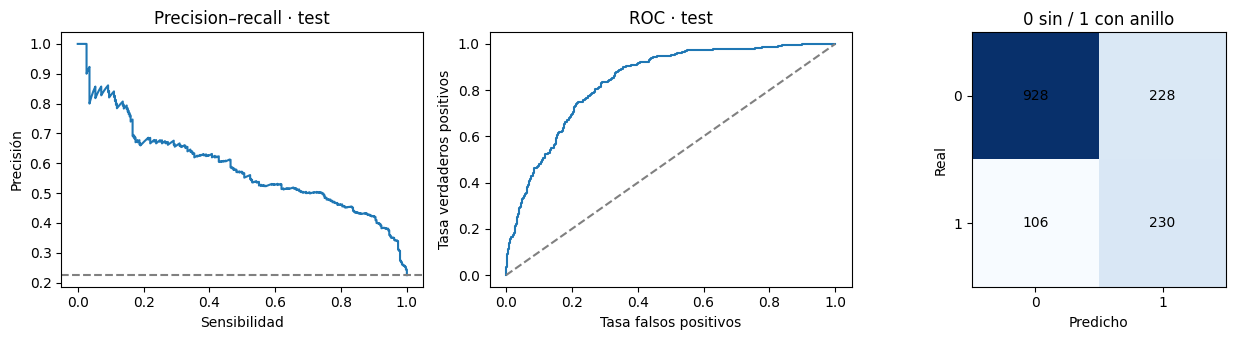

In [11]:
# Visualizaciones sólo si se entrenó el modelo real en esta sesión.
if resultado_modelo is not None:
    import matplotlib.pyplot as plt
    pred=resultado_modelo['test_predictions'];y=pred.target_binario.to_numpy();p=pred.score_con_anillo.to_numpy()
    precision,recall,_=precision_recall_curve(y,p);fpr,tpr,_=roc_curve(y,p)
    fig,axes=plt.subplots(1,3,figsize=(13,3.5))
    axes[0].plot(recall,precision);axes[0].axhline(y.mean(),ls='--',color='gray')
    axes[0].set(xlabel='Sensibilidad',ylabel='Precisión',title='Precision–recall · test')
    axes[1].plot(fpr,tpr);axes[1].plot([0,1],[0,1],'--',color='gray')
    axes[1].set(xlabel='Tasa falsos positivos',ylabel='Tasa verdaderos positivos',title='ROC · test')
    cm=np.array(resultado_modelo['summary']['metricas_test']['confusion_matrix'])
    axes[2].imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2):axes[2].text(j,i,str(cm[i,j]),ha='center',va='center')
    axes[2].set(xticks=[0,1],yticks=[0,1],xlabel='Predicho',ylabel='Real',title='0 sin / 1 con anillo')
    plt.tight_layout();fig.savefig(carpeta_modelo/'evaluacion_test.png',dpi=160);plt.show()
    # Actualizar checksums localmente tras agregar la figura; archivo nuevo, sin reemplazar el anterior.
    (carpeta_modelo/'checksums_con_figura.json').write_bytes(mjson({
        p.name:msha(p.read_bytes()) for p in carpeta_modelo.iterdir() if p.is_file()}))


In [12]:
#@title Tablas para la entrega (no vuelve a entrenar)
# Si reiniciaste Colab, sube comparativa.csv, ajustados.csv y metricas.json
# de la MISMA ejecución a una carpeta e indica aquí su ruta.
CARPETA_RESULTADOS_TABLAS = '' #@param {type:"string"}
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown

if globals().get('resultado_modelo') is not None:
    comparativa_tabla = resultado_modelo['comparativa'].copy()
    ajustados_tabla = resultado_modelo['ajustados'].copy()
    resumen_tablas = resultado_modelo['summary']
elif CARPETA_RESULTADOS_TABLAS.strip():
    ruta_tablas = Path(CARPETA_RESULTADOS_TABLAS)
    comparativa_tabla = pd.read_csv(ruta_tablas/'comparativa.csv')
    ajustados_tabla = pd.read_csv(ruta_tablas/'ajustados.csv')
    resumen_tablas = json.loads((ruta_tablas/'metricas.json').read_text())
else:
    comparativa_tabla = None
    print('Ejecuta esta celda después de entrenar, o indica una carpeta con los tres reportes de la misma ejecución. No se inicia entrenamiento.')

if comparativa_tabla is not None:
    nombres_tablas = {
        'modelo':'Modelo','average_precision':'AP media CV','ap_std':'Desviación AP',
        'roc_auc':'ROC AUC CV','precision':'Precisión CV','recall':'Sensibilidad CV',
        'f1':'F1 CV','balanced_accuracy':'Exactitud balanceada CV',
        'fit_seconds':'Entrenamiento medio/fold (s)',
        'predict_seconds':'Predicción media/fold (s)',
        'warnings_count':'Folds con advertencias','ap_inicial':'AP inicial CV',
        'mejora_ap':'Cambio AP','parametros':'Parámetros elegidos',
        'consideraciones':'Interpretabilidad y limitaciones'}
    def mostrar_tabla_modelos(titulo, tabla):
        display(Markdown('### '+titulo))
        vista = tabla.rename(columns=nombres_tablas)
        formato = {c:'{:.4f}' for c in vista.select_dtypes(include='floating').columns}
        display(vista.style.format(formato, na_rep='No disponible').hide(axis='index'))

    orden = ['average_precision','predict_seconds','modelo']
    comparativa_tabla = comparativa_tabla.sort_values(orden,ascending=[False,True,True])
    columnas = ['modelo','average_precision','ap_std','roc_auc','precision','recall','f1',
                'balanced_accuracy','fit_seconds','predict_seconds','warnings_count']
    mostrar_tabla_modelos('Tabla 1. Comparación de los modelos individuales',comparativa_tabla[columnas])
    display(Markdown('Métricas de validación cruzada de entrenamiento, con umbral 0.5. '
                    'Los tiempos corresponden a un fold completo. La desviación entre folds no es un intervalo de confianza.'))

    ajustados_tabla = ajustados_tabla.sort_values(orden,ascending=[False,True,True])
    mostrar_tabla_modelos('Tabla 2. Los dos finalistas antes y después del ajuste',
        ajustados_tabla[['modelo','ap_inicial','average_precision','mejora_ap','ap_std',
                         'roc_auc','f1','recall','fit_seconds','predict_seconds','warnings_count']])
    mostrar_tabla_modelos('Tabla 3. Configuración y limitaciones de los finalistas',
                         ajustados_tabla[['modelo','parametros','consideraciones']])
    display(Markdown('El cambio de AP se calcula con los mismos folds usados para buscar parámetros: '
                    'es descriptivo y puede ser optimista. Un cambio de cero significa que no se encontró mejora.'))

    valores_test = resumen_tablas['metricas_test']
    filas_test = [('Average Precision','average_precision'),('ROC AUC','roc_auc'),
                 ('Precisión','precision'),('Sensibilidad','recall'),('F1','f1'),
                 ('Exactitud balanceada','balanced_accuracy'),('Proporción con anillo','prevalencia_positiva')]
    tabla_test = pd.DataFrame([{'Métrica':etiqueta,'Valor':valores_test[clave]} for etiqueta,clave in filas_test])
    mostrar_tabla_modelos('Tabla 4. Evaluación del modelo individual final en test',tabla_test)
    display(Markdown(f"**Modelo final:** {resumen_tablas['modelo_elegido']} · "
                     f"**Umbral:** {resumen_tablas['umbral']:.4f} · **Galaxias de prueba:** {resumen_tablas['n_test']}.\n\n"
                     +resumen_tablas['justificacion']))
    display(Markdown('La tabla de test corresponde únicamente al modelo elegido; no se utiliza para volver a seleccionar entre los algoritmos.'))


### Tabla 1. Comparación de los modelos individuales

Modelo,AP media CV,Desviación AP,ROC AUC CV,Precisión CV,Sensibilidad CV,F1 CV,Exactitud balanceada CV,Entrenamiento medio/fold (s),Predicción media/fold (s),Folds con advertencias
MLP,0.5627,0.0549,0.8109,0.5745,0.4929,0.5289,0.6927,13.3795,0.0115,0
SVM,0.5607,0.0478,0.8251,0.6054,0.4349,0.5047,0.6762,7.5835,0.4349,5
RegresionLogistica,0.5478,0.0531,0.8109,0.4389,0.7695,0.5589,0.7417,0.7509,0.0261,0
KNN,0.4879,0.0347,0.7853,0.5872,0.3546,0.4415,0.6412,0.0914,0.1471,0
ViT_B16,0.4624,0.0254,0.7385,0.4000,0.5970,0.4789,0.6680,2.2975,0.0276,0
CNN_ResNet18,0.4408,0.0348,0.7147,0.3738,0.5978,0.4597,0.6533,1.1972,0.0251,0
ArbolDecision,0.4199,0.0181,0.7203,0.4290,0.6796,0.5257,0.7080,0.6689,0.0168,0
GaussianNB,0.2998,0.0073,0.6470,0.2640,0.9346,0.4117,0.5883,0.0944,0.0163,0


Métricas de validación cruzada de entrenamiento, con umbral 0.5. Los tiempos corresponden a un fold completo. La desviación entre folds no es un intervalo de confianza.

### Tabla 2. Los dos finalistas antes y después del ajuste

Modelo,AP inicial CV,AP media CV,Cambio AP,Desviación AP,ROC AUC CV,F1 CV,Sensibilidad CV,Entrenamiento medio/fold (s),Predicción media/fold (s),Folds con advertencias
MLP,0.5627,0.5866,0.0239,0.0674,0.8283,0.5118,0.4312,15.0194,0.0134,5
SVM,0.5607,0.5607,0.0000,0.0478,0.8251,0.5047,0.4349,7.5835,0.4349,5


...

El cambio de AP se calcula con los mismos folds usados para buscar parámetros: es descriptivo y puede ser optimista. Un cambio de cero significa que no se encontró mejora.

### Tabla 4. Evaluación del modelo individual final en test

Métrica,Valor
Average Precision,0.5890
ROC AUC,0.8394
Precisión,0.5022
Sensibilidad,0.6845
F1,0.5793
Exactitud balanceada,0.7436
Proporción con anillo,0.2252


**Modelo final:** MLP · **Umbral:** 0.3100 · **Galaxias de prueba:** 1492.

Se elige MLP por AP media CV=0.5866, frente a SVM=0.5607. F1 CV a umbral 0.5=0.5118; sensibilidad=0.4312; ajuste medio/fold=15.019s; inferencia media/fold=0.013s. Red neuronal individual; no lineal, poco interpretable y sensible a convergencia. Se prioriza el ranking de candidatos con anillo; se acepta esta limitación de interpretación/coste. Las diferencias de CV son descriptivas, no prueba de significación. Revisar alertas de convergencia antes de entregar.

La tabla de test corresponde únicamente al modelo elegido; no se utiliza para volver a seleccionar entre los algoritmos.

## 5. Exportar a GCP opcionalmente
El modelo se guarda primero localmente. Activar la casilla siguiente autoriza crear objetos bajo `models/v1/<nombre_ejecucion>/`; no se modifica ninguna imagen ni resultado previo. Para guardar sin GCP, descargar el directorio desde Colab.

`modelo.joblib` incluye el pipeline de imputación y clasificador, las 84 columnas en orden y el umbral seleccionado. Cargar únicamente modelos propios/de confianza: joblib no es un formato seguro para archivos de procedencia desconocida. Registrar versiones; un modelo puede no ser portable entre versiones distintas de las bibliotecas.


In [13]:
#@title Guardar el entrenamiento en GCP (opcional)
GUARDAR_MODELO_GCP = True #@param {type:"boolean"}
if GUARDAR_MODELO_GCP:
    if carpeta_modelo is None:raise ValueError('Primero entrenar y guardar localmente')
    from google.cloud import storage
    from google.api_core.exceptions import PreconditionFailed
    import google.auth
    if cliente_modelo is None:
        if ENTORNO=='Colab':
            from google.colab import auth
            auth.authenticate_user(project_id=PROYECTO)
        credentials,_=google.auth.default()
        cliente_modelo=storage.Client(project=PROYECTO,credentials=credentials)
    bucket_modelo=cliente_modelo.get_bucket(BUCKET,timeout=120)
    if bucket_modelo.location.lower()!='us-central1':raise ValueError('Región inesperada')
    prefix=f'models/v1/{carpeta_modelo.name}/'
    for archivo in sorted(carpeta_modelo.iterdir()):
        if not archivo.is_file():continue
        data=archivo.read_bytes();blob=bucket_modelo.blob(prefix+archivo.name)
        blob.metadata={'sha256':msha(data)}
        try:blob.upload_from_string(data,if_generation_match=0,checksum=None,timeout=120)
        except PreconditionFailed:pass
        blob.reload()
        checked=blob.download_as_bytes(if_generation_match=int(blob.generation),checksum='crc32c',timeout=120)
        if msha(checked)!=msha(data):raise ValueError('Conflicto en objeto existente: '+blob.name)
    print('Modelo y reportes:',f'gs://{BUCKET}/{prefix}')
else:
    print('Exportación GCP desactivada.')


Modelo y reportes: gs://galmorphai-science/models/v1/20261026T081634-6de4d5f5370a/


# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| OpenAI. (2026). ChatGPT / Codex [Asistente de inteligencia artificial]. https://chatgpt.com/ | Apoyo en diseño del protocolo, generación y modificación de código, documentación y pruebas sintéticas; adaptación a la rúbrica. | Secciones 1–7: validaciones de datos, seis clasificadores tabulares y extensión CNN/ViT con extractores congelados, comparación, ajuste de dos, selección, reportes y esta declaración. | El usuario proporcionó la semántica de anillos y solicitó la adaptación a la rúbrica. Las pruebas locales automatizadas fueron ejecutadas por el asistente.|


### Decisiones principales

**Decisión 1: comparar modelos individuales e incorporar CNN/ViT por indicación del asesor.**
- Justificación: satisfacer el criterio más exigente de la rúbrica y comparar fronteras lineales, probabilísticas, por vecinos, árboles y redes neuronales.
- Alternativa descartada y motivo: mantener Random Forest y XGBoost, porque son ensambles y se reservan para el avance 5. Se incorporan CNN y ViT con transferencia de aprendizaje; su ajuste se limita a la cabeza, no a las capas del extractor.

**Decisión 2: seleccionar y ajustar usando solamente entrenamiento.**
- Justificación: usar los mismos folds para comparar y buscar hiperparámetros de los dos finalistas, preservando test para la evaluación final.
- Alternativa descartada y motivo: elegir parámetros o algoritmo según resultados de test, porque contaminaría la estimación de generalización.

**Decisión 3: conservar la semántica original y modelar presencia de anillos en este avance.**
- Justificación: derivar el objetivo binario acordado manteniendo códigos originales y resultados por subtipo para conocer limitaciones.
- Alternativa descartada y motivo: tratar los códigos como números ordinales o afirmar clasificación de tipos/barras, porque no corresponde al objetivo ni a la evidencia de este experimento.
